<a href="https://colab.research.google.com/github/Gagandeep1227/ML-2/blob/main/SHAP%2CLIME.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
pip install numpy pandas matplotlib scikit-learn shap

Dataset Loaded Successfully!

First 5 Records:
   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
0                5.1               3.5                1.4               0.2
1                4.9               3.0                1.4               0.2
2                4.7               3.2                1.3               0.2
3                4.6               3.1                1.5               0.2
4                5.0               3.6                1.4               0.2

Training Samples: 120
Testing Samples: 30

Model Training Completed!

Model Accuracy: 90.0 %

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.82      0.90      0.86        10
   virginica       0.89      0.80      0.84        10

    accuracy                           0.90        30
   macro avg       0.90      0.90      0.90        30
weighted avg       0.90      0.90      0.90        30

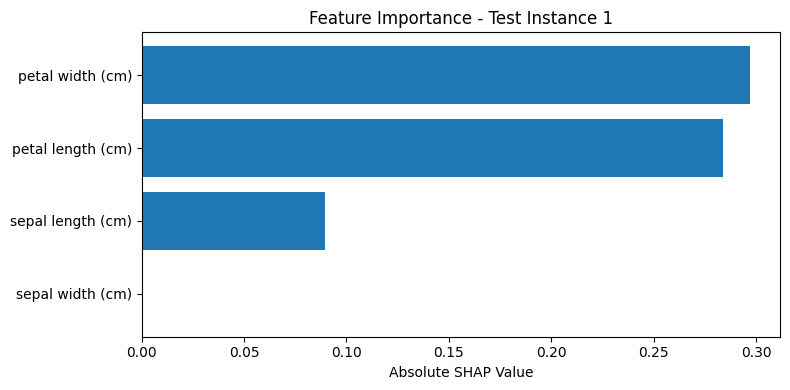


Test Instance: 2
Input Features:
sepal length (cm)    6.1
sepal width (cm)     3.0
petal length (cm)    4.9
petal width (cm)     1.8
Name: 127, dtype: float64
Actual Class: virginica
Predicted Class: virginica

Feature Importance:
          Feature  SHAP Value  Absolute Importance
 petal width (cm)    0.357703             0.357703
petal length (cm)    0.155838             0.155838
 sepal width (cm)    0.009059             0.009059
sepal length (cm)   -0.000100             0.000100


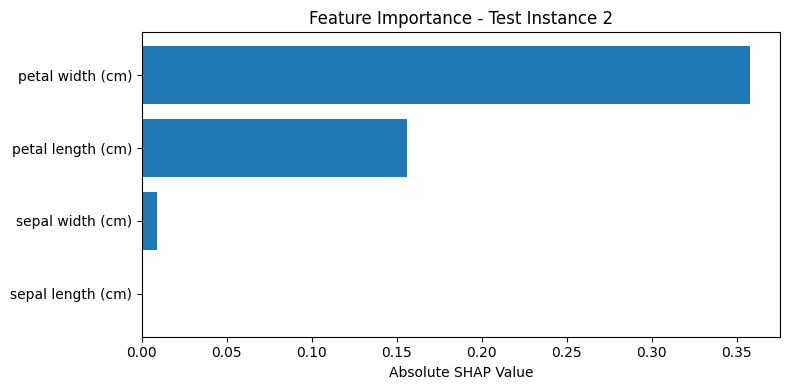


SHAP Interpretation Completed Successfully!


In [ ]:
# MACHINE LEARNING MODEL INTERPRETATION USING SHAP

# Step 1: Import libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

# Step 2: Load the Iris dataset
iris = load_iris()

X = pd.DataFrame(
    iris.data,
    columns=iris.feature_names
)

y = pd.Series(iris.target, index=X.index)

print("Dataset Loaded Successfully!")
print("\nFirst 5 Records:")
print(X.head())

# Step 3: Split the dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("\nTraining Samples:", len(X_train))
print("Testing Samples:", len(X_test))

# Step 4: Train Random Forest model
model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

model.fit(X_train, y_train)

print("\nModel Training Completed!")

# Step 5: Evaluate the model
y_pred = model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)

print("\nModel Accuracy:", round(accuracy * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=iris.target_names
))

# Step 6: Create SHAP explainer
explainer = shap.TreeExplainer(model)

# Step 7: Select two test instances
test_instances = X_test.iloc[:2]

# Calculate SHAP values
shap_values = explainer.shap_values(test_instances)

print("\nSHAP Analysis for Two Test Instances")

# Step 8: Display predictions
predictions = model.predict(test_instances)

for i in range(2):

    print("\nTest Instance:", i + 1)

    print("Input Features:")
    print(test_instances.iloc[i])

    print(
        "Actual Class:",
        iris.target_names[y_test.loc[test_instances.index[i]]]
    )

    print(
        "Predicted Class:",
        iris.target_names[predictions[i]]
    )

    print("\nFeature Importance:")

    # SHAP values for the predicted class
    class_index = predictions[i]

    if isinstance(shap_values, list):
        values = shap_values[class_index][i]
    else:
        values = shap_values[i, :, class_index]

    importance = pd.DataFrame({
        "Feature": X.columns,
        "SHAP Value": values,
        "Absolute Importance": np.abs(values)
    })

    importance = importance.sort_values(
        by="Absolute Importance",
        ascending=False
    )

    print(importance.to_string(index=False))

    # Plot feature importance
    plt.figure(figsize=(8, 4))

    plt.barh(
        importance["Feature"],
        importance["Absolute Importance"]
    )

    plt.xlabel("Absolute SHAP Value")
    plt.title(f"Feature Importance - Test Instance {i+1}")
    plt.gca().invert_yaxis()
    plt.tight_layout()
    plt.show()

print("\nSHAP Interpretation Completed Successfully!")

In [ ]:
pip install pandas numpy matplotlib scikit-learn shap

Loading dataset...

Dataset Loaded Successfully!
Dataset Shape: (569, 33)

First 5 Records:
         id diagnosis  radius_mean  texture_mean  perimeter_mean  area_mean  \
0    842302         M        17.99         10.38          122.80     1001.0   
1    842517         M        20.57         17.77          132.90     1326.0   
2  84300903         M        19.69         21.25          130.00     1203.0   
3  84348301         M        11.42         20.38           77.58      386.1   
4  84358402         M        20.29         14.34          135.10     1297.0   

   smoothness_mean  compactness_mean  concavity_mean  concave points_mean  \
0          0.11840           0.27760          0.3001              0.14710   
1          0.08474           0.07864          0.0869              0.07017   
2          0.10960           0.15990          0.1974              0.12790   
3          0.14250           0.28390          0.2414              0.10520   
4          0.10030           0.13280          0.

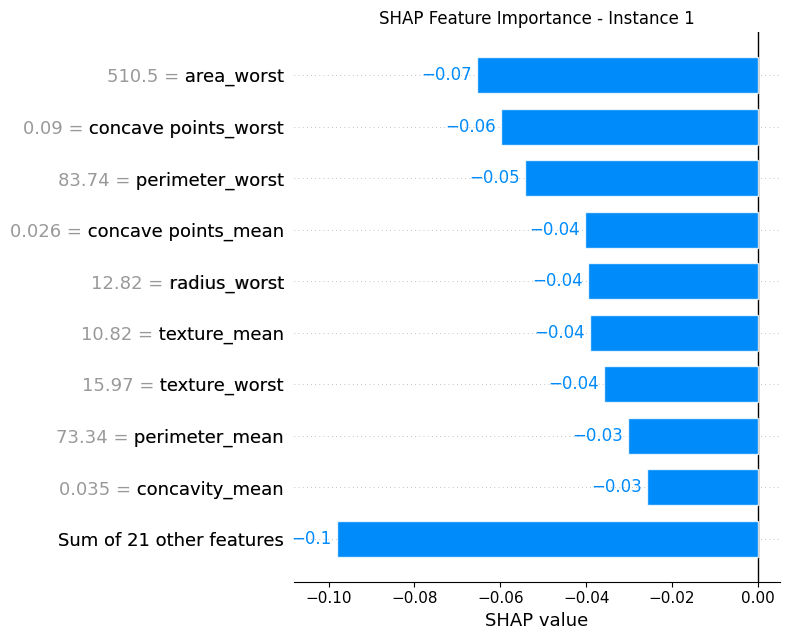

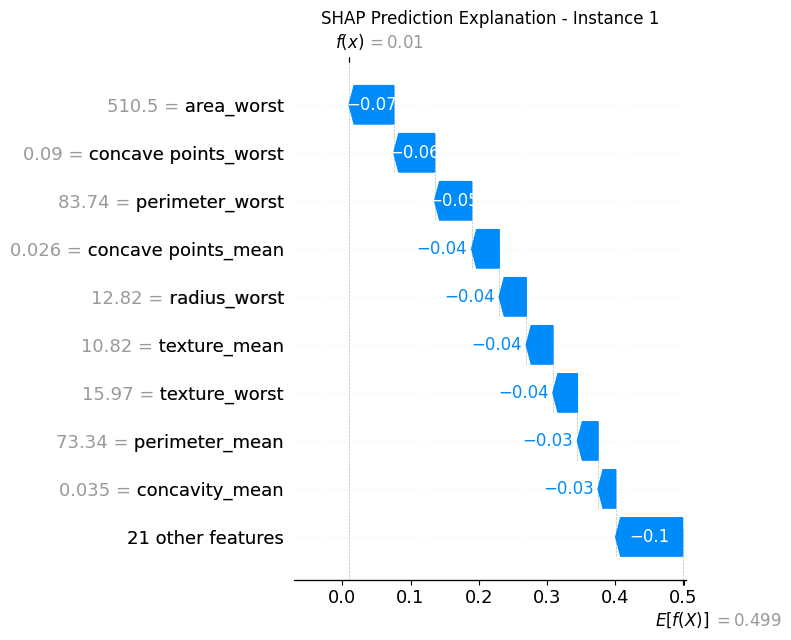


TEST INSTANCE: 2

Input Features:
radius_mean                  20.940000
texture_mean                 23.560000
perimeter_mean              138.900000
area_mean                  1364.000000
smoothness_mean               0.100700
compactness_mean              0.160600
concavity_mean                0.271200
concave points_mean           0.131000
symmetry_mean                 0.220500
fractal_dimension_mean        0.058980
radius_se                     1.004000
texture_se                    0.820800
perimeter_se                  6.372000
area_se                     137.900000
smoothness_se                 0.005283
compactness_se                0.039080
concavity_se                  0.095180
concave points_se             0.018640
symmetry_se                   0.024010
fractal_dimension_se          0.005002
radius_worst                 25.580000
texture_worst                27.000000
perimeter_worst             165.300000
area_worst                 2010.000000
smoothness_worst             

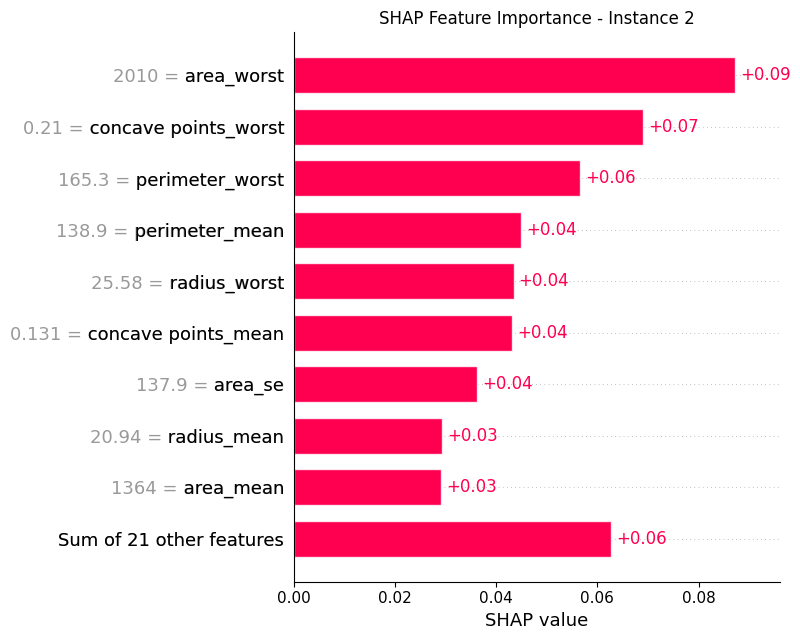

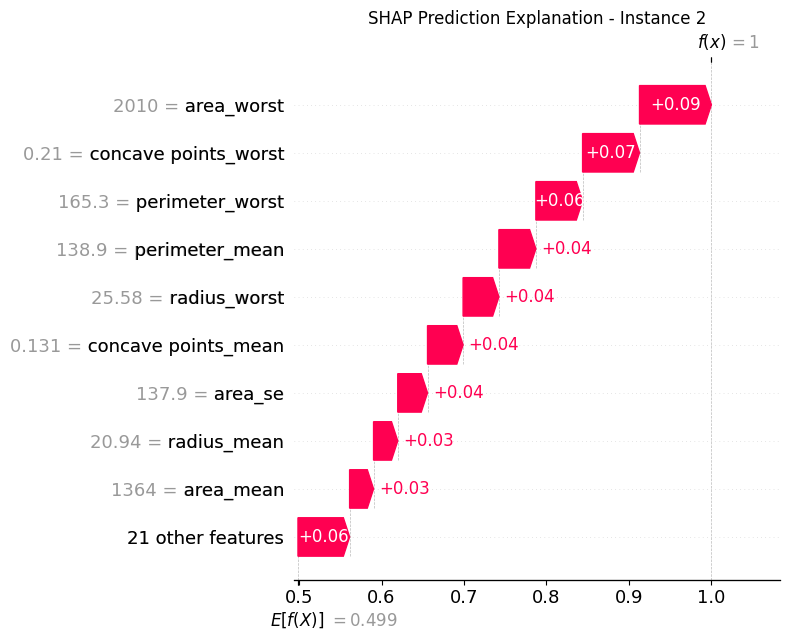


GLOBAL FEATURE IMPORTANCE:
             Feature  Mean_Absolute_SHAP
          area_worst            0.076313
concave points_worst            0.064428
     perimeter_worst            0.055467
 concave points_mean            0.041742
        radius_worst            0.041537
      perimeter_mean            0.037543
             area_se            0.029810
      concavity_mean            0.026982
         radius_mean            0.024067
        texture_mean            0.023335

SHAP Analysis Completed Successfully!
Individual results saved to shap_feature_importance.csv
Global results saved to global_shap_importance.csv


In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

print("Loading dataset...")

df = pd.read_csv("data.csv")

print("\nDataset Loaded Successfully!")
print("Dataset Shape:", df.shape)
print("\nFirst 5 Records:")
print(df.head())

df = df.drop(columns=["id", "Unnamed: 32"], errors="ignore")

df = df.dropna()

X = df.drop(columns=["diagnosis"])

y = df["diagnosis"].map({"B": 0, "M": 1})

if y.isna().any():
    raise ValueError("Unexpected diagnosis labels in dataset.")

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("\nTraining Samples:", len(X_train))
print("Testing Samples:", len(X_test))

model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    class_weight="balanced"
)

model.fit(X_train, y_train)

print("\nModel Training Completed!")

y_pred = model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)

print("\nModel Accuracy:", round(accuracy * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["Benign", "Malignant"]
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

explainer = shap.TreeExplainer(model)

test_instances = X_test.iloc[:2].copy()

shap_values = explainer.shap_values(test_instances)

if isinstance(shap_values, list):
    malignant_values = shap_values[1]
elif shap_values.ndim == 3:
    malignant_values = shap_values[:, :, 1]
else:
    malignant_values = shap_values

base_values = np.asarray(explainer.expected_value)

if base_values.ndim > 0 and base_values.size > 1:
    base_value = float(base_values[1])
else:
    base_value = float(base_values.reshape(-1)[0])

all_results = []

for i in range(2):

    print("\n================================")
    print("TEST INSTANCE:", i + 1)
    print("================================")

    instance = test_instances.iloc[i]
    predicted = model.predict(instance.to_frame().T)[0]

    actual = y_test.loc[instance.name]

    print("\nInput Features:")
    print(instance)

    print("\nActual Class:",
          "Malignant" if actual == 1 else "Benign")

    print("Predicted Class:",
          "Malignant" if predicted == 1 else "Benign")

    print("Prediction Probability:",
          model.predict_proba(instance.to_frame().T)[0])


    importance = pd.DataFrame({
        "Feature": X.columns,
        "SHAP_Value": malignant_values[i],
        "Absolute_Importance": np.abs(malignant_values[i])
    })

    importance = importance.sort_values(
        by="Absolute_Importance",
        ascending=False
    )

    print("\nTop 10 Important Features:")
    print(importance.head(10).to_string(index=False))

    importance["Test_Instance"] = i + 1
    all_results.append(importance)

    explanation = shap.Explanation(
        values=malignant_values[i],
        base_values=base_value,
        data=instance.values,
        feature_names=X.columns.tolist()
    )

    plt.figure()
    shap.plots.bar(explanation, max_display=10, show=False)
    plt.title(f"SHAP Feature Importance - Instance {i+1}")
    plt.tight_layout()
    plt.show()

    plt.figure()
    shap.plots.waterfall(
        explanation,
        max_display=10,
        show=False
    )
    plt.title(f"SHAP Prediction Explanation - Instance {i+1}")
    plt.tight_layout()
    plt.show()

final_results = pd.concat(all_results, ignore_index=True)

final_results.to_csv(
    "shap_feature_importance.csv",
    index=False
)

global_importance = pd.DataFrame({
    "Feature": X.columns,
    "Mean_Absolute_SHAP": np.abs(malignant_values).mean(axis=0)
})

global_importance = global_importance.sort_values(
    by="Mean_Absolute_SHAP",
    ascending=False
)

print("\nGLOBAL FEATURE IMPORTANCE:")
print(global_importance.head(10).to_string(index=False))

global_importance.to_csv(
    "global_shap_importance.csv",
    index=False
)

print("\nSHAP Analysis Completed Successfully!")
print("Individual results saved to shap_feature_importance.csv")
print("Global results saved to global_shap_importance.csv")
